# 02 - Data Preprocessing

**Coursework Part 01, Task 2.I**

**Goal:** turn the raw Kaggle file into a clean, consistent dataset and a stratified train/test split that the modelling notebook can use directly. Each step is justified using what was found in the EDA notebook.

**What happens here and what does not**

| Done in this notebook (data-level fixes) | Done in the modelling notebook |
|---|---|
| Fix data types, handle missing values, remove the ID, standardise categories, check duplicates and outliers, encode the target, train/test split | One-hot encoding, and scaling |

Encoding, and scaling *learn* something from the data (category lists, means, standard deviations, neighbours). If they were fitted on the full dataset before splitting, information from the test set would leak into training. Below section show how they work, fitted on the training set only, but the saved files stay unencoded so the pipeline can refit them inside each cross-validation fold.

## Setup

In [1]:
import sys
sys.path.append("..")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from src.cm2604_ml_cw.preprocessing import encode

sns.set_theme(style = "whitegrid", context = "notebook")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 20080227
TEST_SIZE = 0.2

RAW_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
CLEAN_PATH = Path("../data/processed/telco_churn_clean.csv")
TRAIN_PATH = Path("../data/processed/train.csv")
TEST_PATH = Path("../data/processed/test.csv")

## Load The Raw Data

In [2]:
df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()   # keep the original untouched for before/after comparisons

print(f"Raw shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Raw shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Fix Data Types

`TotalCharges` should be numeric but is stored as text (`object`/`str`). Converting it with `errors="coerce"` turns any value that is not a valid number into `NaN`, which exposes the hidden problem values.

In [3]:
print("TotalCharges dtype before:", df["TotalCharges"].dtype)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges dtype after :", df["TotalCharges"].dtype)
print("Values that could not be converted:", df["TotalCharges"].isna().sum())

TotalCharges dtype before: str
TotalCharges dtype after : float64
Values that could not be converted: 11


## Handle Missing Values

In [4]:
missing = df.isna().sum()
missing[missing > 0]

TotalCharges    11
dtype: int64

All 11 blank values belong to the only 11 customers with tenure = 0. They have just joined and have not received a bill yet, so their true total charge is 0. This is not a guess.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing values remaining:", df.isna().sum().sum())

Missing values remaining: 0


## Remove The Identifier Column

In [6]:
print("Unique customerIDs:", df["customerID"].nunique(), "of", len(df))
df = df.drop(columns="customerID")

Unique customerIDs: 7043 of 7043


## Standardize Categorical Values

In [7]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

# Check for stray whitespace or inconsistent capitalisation
for col in cat_cols:
    values = df[col].unique()
    stripped = {v.strip() for v in values}
    lowered = {v.strip().lower() for v in values}
    if len(stripped) != len(values) or len(lowered) != len(values):
        print(f"Inconsistent values in {col}: {values}")
print("Whitespace/case check complete.")

Whitespace/case check complete.


In [8]:
# SeniorCitizen is the only binary feature stored as 0/1; every other one uses Yes/No.
# Converting it means all categorical features are treated the same way by the encoder.
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

## Check Duplicates

In [9]:
dupes = df.duplicated(keep=False)
print("Rows that exactly duplicate another row:", df.duplicated().sum())
df[dupes].sort_values(["tenure", "MonthlyCharges"]).head(6)

Rows that exactly duplicate another row: 22


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
542,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
5170,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
6774,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
4817,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.90,No
6706,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.90,No


Before `customerID` was removed, every row was a different customer. These duplicates are separate customers who happen to have the same plan, services and charges. All of them have a `tenure` of 1 month, and most are on low-cost plans without internet, so identical combinations are likely. Removing them would delete real customers and slightly distort the data.

## Check Outliers
The interquartile range (IQR) rule flags values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR.

In [10]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({"feature": col, "min": df[col].min(), "max": df[col].max(),
                 "lower_bound": round(low, 2), "upper_bound": round(high, 2), "outliers": n_out})
pd.DataFrame(rows)

,feature,min,max,lower_bound,upper_bound,outliers
0,tenure,0.00,72.00,-60.00,124.00,0
1,MonthlyCharges,18.25,118.75,-46.02,171.38,0
2,TotalCharges,0.00,8684.80,-4683.52,8868.67,0


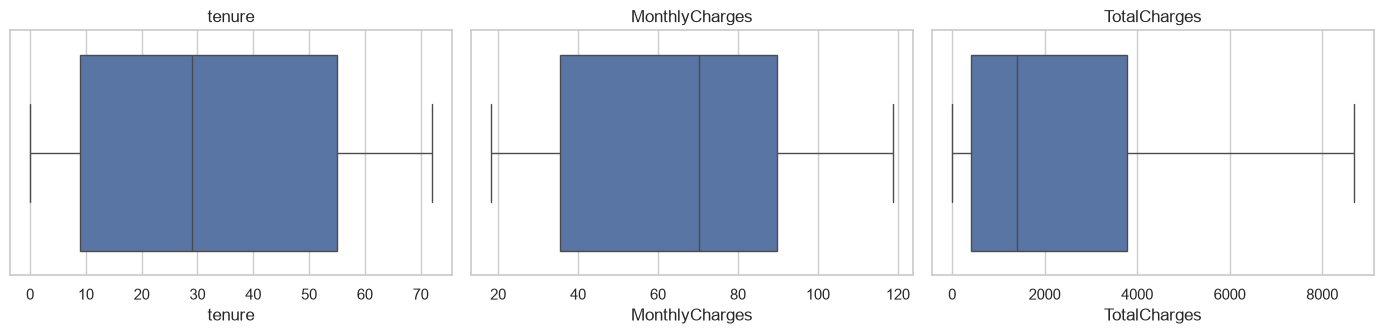

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.show()

No outliers in any numerical feature. All values are also within realistic ranges. No action is needed.

`TotalCharges` is right-skewed, but that reflects real behaviour (many new customers) rather than errors. Standard scaling in the pipeline is enough for KNN and Logistic Regression. Random Forest is unaffected by skew.

## Check Redundant Categories

Six service columns have a third value, "No internet service", and `MultipleLines` has "No phone service". These should match `InternetService == "No"` and `PhoneService == "No"` exactly.

In [12]:
internet_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]

no_internet = df["InternetService"] == "No"
for col in internet_cols:
    match = ((df[col] == "No internet service") == no_internet).all()
    print(f"{col:<17} 'No internet service' matches InternetService == 'No': {match}")

no_phone = df["PhoneService"] == "No"
match = ((df["MultipleLines"] == "No phone service") == no_phone).all()
print(f"{'MultipleLines':<17} 'No phone service' matches PhoneService == 'No'   : {match}")

OnlineSecurity    'No internet service' matches InternetService == 'No': True
OnlineBackup      'No internet service' matches InternetService == 'No': True
DeviceProtection  'No internet service' matches InternetService == 'No': True
TechSupport       'No internet service' matches InternetService == 'No': True
StreamingTV       'No internet service' matches InternetService == 'No': True
StreamingMovies   'No internet service' matches InternetService == 'No': True
MultipleLines     'No phone service' matches PhoneService == 'No'   : True


The values are fully consistent, so there is no error to fix. The EDA showed these groups behave very differently (about 42% vs 7% churn).

After one-hot encoding, these columns are perfectly correlated with `InternetService_No`.

## Encode The Target

In [13]:
print(df["Churn"].value_counts())

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print()
print(df["Churn"].value_counts())
print(f"Churn rate: {df['Churn'].mean():.2%}")

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 26.54%


## Final checks

In [14]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns  (raw: {df_raw.shape[0]:,} x {df_raw.shape[1]})")
print("Missing values:", df.isna().sum().sum())
print()
print(df.dtypes.value_counts())

Shape: 7,043 rows x 20 columns  (raw: 7,043 x 21)
Missing values: 0

str        16
int64       2
float64     2
Name: count, dtype: int64


In [15]:
# Group the columns for the split and the encoding step
TARGET = "Churn"
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]

assert df[num_cols].apply(pd.api.types.is_numeric_dtype).all()
assert df[TARGET].isin([0, 1]).all()
assert df.isna().sum().sum() == 0

print(f"Numerical features   ({len(num_cols)}):", num_cols)
print(f"Categorical features ({len(cat_cols)}):", cat_cols)

Numerical features   (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [16]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Train/Test Split And Save
The split is **stratified** on `Churn`, so both sets keep the same ~26.5% churn rate. Without stratification, a random split could give the test set noticeably more or fewer churners, which would make the evaluation less reliable.

In [17]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "rows": [len(y), len(y_train), len(y_test)],
    "churned": [y.sum(), y_train.sum(), y_test.sum()],
    "churn_rate": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["full", "train", "test"])
split_summary.style.format({"churn_rate": "{:.2%}", "rows": "{:,}", "churned": "{:,}"})

,rows,churned,churn_rate
full,"7,043","1,869",26.54%
train,"5,634","1,495",26.54%
test,"1,409",374,26.54%


In [18]:
df.to_csv(CLEAN_PATH, index=False)
pd.concat([X_train, y_train], axis=1).to_csv(TRAIN_PATH, index=False)
pd.concat([X_test, y_test], axis=1).to_csv(TEST_PATH, index=False)

for path in [CLEAN_PATH, TRAIN_PATH, TEST_PATH]:
    print(f"Saved {path}")

Saved ..\data\processed\telco_churn_clean.csv
Saved ..\data\processed\train.csv
Saved ..\data\processed\test.csv


## Encoding And Scaling (Fitted On Training Data Only)

In [19]:
# Fit on the training set ONLY, then apply the same transformation to the test set
X_train_prep, X_test_prep, preprocessor = encode(X_train, X_test, scale=True)

Scaling applied         : True
Features before encoding: 19
Features after encoding : 40

['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Cre

In [20]:
X_train_prep.head()

,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
5175,-0.508491,-1.473451,-0.835833,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4824,1.617064,1.073232,2.131960,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2840,-0.385863,0.647681,-0.156098,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4804,1.167428,1.780276,2.234380,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
5437,-0.508491,-0.107382,-0.491848,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [21]:
# Scaling check: the training set is exactly mean 0 / std 1.
# The test set is close but not exact, because it was transformed with the
# training set's mean and std. This is the expected sign that no test data leaked in.
pd.DataFrame({
    "train_mean": X_train_prep[num_cols].mean(),
    "train_std": X_train_prep[num_cols].std(ddof=0),
    "test_mean": X_test_prep[num_cols].mean(),
    "test_std": X_test_prep[num_cols].std(ddof=0),
}).round(3)

,train_mean,train_std,test_mean,test_std
tenure,-0.0,1.0,-0.014,1.019
MonthlyCharges,-0.0,1.0,-0.013,0.982
TotalCharges,0.0,1.0,-0.026,0.990


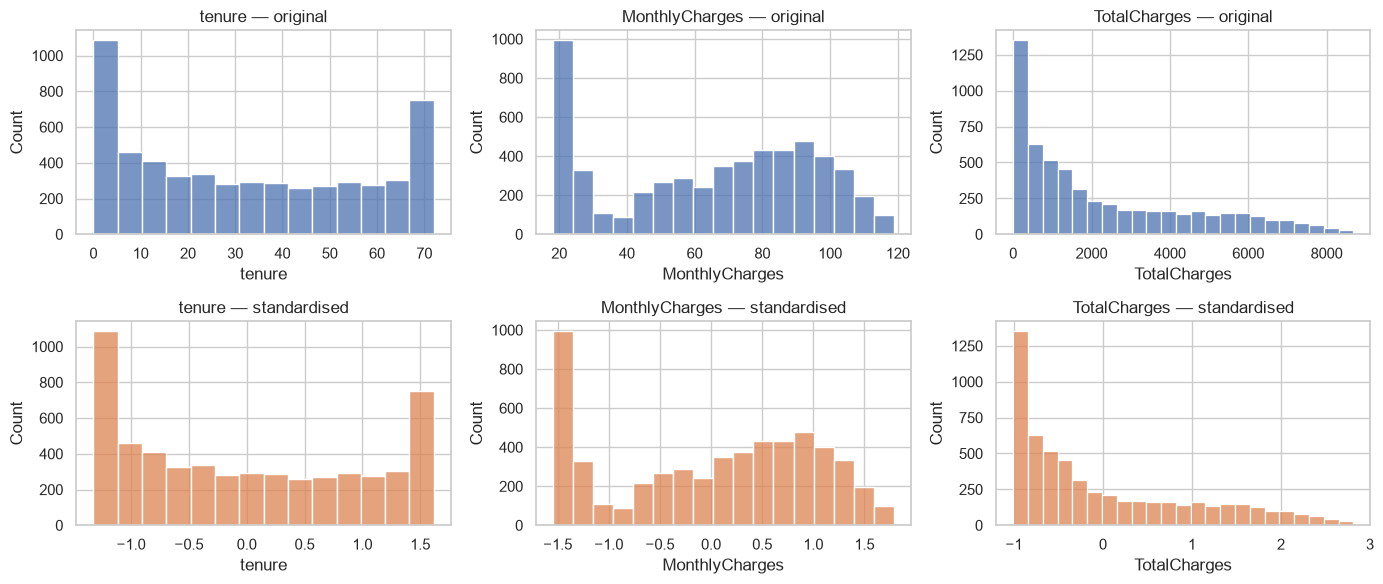

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for i, col in enumerate(num_cols):
    sns.histplot(X_train[col], ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{col} — original")
    sns.histplot(X_train_prep[col], ax=axes[1, i], color="#DD8452")
    axes[1, i].set_title(f"{col} — standardised")
plt.tight_layout()
plt.show()

## Summary

| Step | Issue found | Action | Justification |
|---|---|---|---|
| Data types | `TotalCharges` stored as text | Converted to numeric | Needed for analysis and modelling |
| Missing values | 11 blank `TotalCharges` | Filled with 0 | All belong to `tenure = 0` customers who have not been billed |
| Identifier | `customerID` unique per row | Dropped | No predictive value; risk of memorisation |
| Inconsistent encoding | `SeniorCitizen` as 0/1, others Yes/No | Mapped to Yes/No | All binary features handled the same way |
| Whitespace / case | None found | - | - |
| Duplicates | 22 identical feature rows | Kept | Different customers with identical plans |
| Outliers | None (IQR rule) | - | All values within realistic ranges |
| Redundant categories | "No internet/phone service" | Kept | Consistent, and carries different churn behaviour |
| Target | `Churn` as Yes/No | Encoded 1/0 | Churn is the positive class for metrics |
| Split | - | Stratified 80/20, `random_state=20080227` | Keeps the churn ratio equal in both sets |
| Encoding / scaling | 16 categorical, 3 numeric on different scales | One-hot + standard scaling | Applied inside the model pipeline, fitted on training data only |

**Output Files**
- `data/processed/telco_churn_clean.csv` :- full cleaned dataset
- `data/processed/train.csv` :- training set (unencoded)
- `data/processed/test.csv` :- test set (unencoded)